# Day 38 | Build an Agent That Uses Tools

**KGP Talkie**

Let an agent manage the model-tool loop, with a clear stopping limit.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

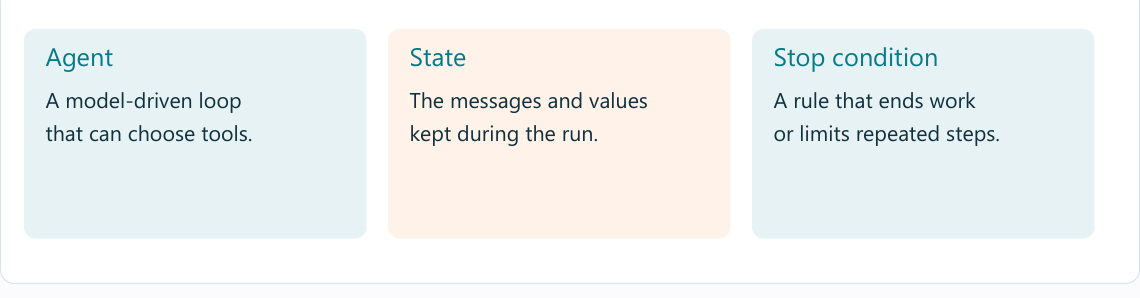

@tool wraps a documented function and exposes its input types as a tool schema.

In [4]:
from langchain_core.tools import tool

The model sees a name, description, and two integer inputs. Python computes the sum.

In [5]:
@tool
def add_numbers(a: int, b: int) -> int:
    """Add two integer numbers and return their exact sum."""
    return a + b

In [6]:
@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integer numbers and return their exact product."""
    return a * b

In [7]:
print(add_numbers.name)
print(add_numbers.args)

add_numbers
{'a': {'title': 'A', 'type': 'integer'}, 'b': {'title': 'B', 'type': 'integer'}}


Test the function directly before a model is allowed to request it.

In [8]:
add_numbers.invoke({"a": 7, "b": 5})

12

ChatOllama sends chat requests to the local Ollama server.

In [9]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [10]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [11]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=256, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [12]:
from langchain.agents import create_agent

In [13]:
agent = create_agent(llm, [add_numbers, multiply], system_prompt="Use real tool calls for all math. Call one tool at a time with integer arguments. Wait for its result before the next call. Never write a tool call as ordinary text. Give the final answer from the last tool result.")

A step limit stops an agent from continuing without end. Ten allows a short classroom tool loop, not a guarantee of completion.

In [14]:
result = agent.invoke({"messages": [{"role": "user", "content": "Use a tool: What is 4 times 6?"}]}, config={"recursion_limit": 10})

Inspect tool requests and computed replies as well as the final message.

In [15]:
[(m.type, m.content, getattr(m, "tool_calls", [])) for m in result["messages"]]

[('human', 'Use a tool: What is 4 times 6?', []),
 ('ai',
  '',
  [{'name': 'multiply',
    'args': {'a': '4', 'b': '6'},
    'id': '6be1c62a-6556-47bc-be3b-97a25b87aaab',
    'type': 'tool_call'}]),
 ('tool', '24', []),
 ('ai', 'The result of 4 times 6 is 24.', [])]

In [16]:
fresh = agent.invoke({"messages": [{"role": "user", "content": "Use add_numbers with a=3 and b=5. Then use multiply with the returned sum as a and 2 as b. Give the final result."}]}, config={"recursion_limit": 12})

In [17]:
print(fresh["messages"][-1].content)

The final result is 16.


The final reply may describe a tool without a real call. Read the actual trace before trusting the calculation.

In [18]:
[(m.type, m.content, getattr(m, "tool_calls", [])) for m in fresh["messages"]]

[('human',
  'Use add_numbers with a=3 and b=5. Then use multiply with the returned sum as a and 2 as b. Give the final result.',
  []),
 ('ai',
  '',
  [{'name': 'add_numbers',
    'args': {'a': '3', 'b': '5'},
    'id': '48103c21-14f1-49b8-b5e4-bc09d19a865d',
    'type': 'tool_call'},
   {'name': 'multiply',
    'args': {'b': '2', 'a': '8'},
    'id': '6328b2c3-ef1a-44bc-9b05-204f791874f2',
    'type': 'tool_call'}]),
 ('tool', '8', []),
 ('tool', '16', []),
 ('ai', 'The final result is 16.', [])]

Only ToolMessage results count as executed tools. A JSON-looking sentence alone does not count.

In [19]:
successful_results = [m.content for m in fresh["messages"] if m.type == "tool" and m.status == "success"]  # Count real results, not tool errors.
print("Successful tool results:", successful_results)
assert "8" in successful_results and "16" in successful_results, "The model skipped a required calculation. Run the example again."

Successful tool results: ['8', '16']


updates shows changed stage names. The course also demonstrates values for the full state.

In [20]:
for event in agent.stream({"messages": [{"role": "user", "content": "Use add_numbers with a=9 and b=2. Give the tool result."}]}, config={"recursion_limit": 10}, stream_mode="updates"):
    print(list(event.keys()))

['model']
['tools']


['model']


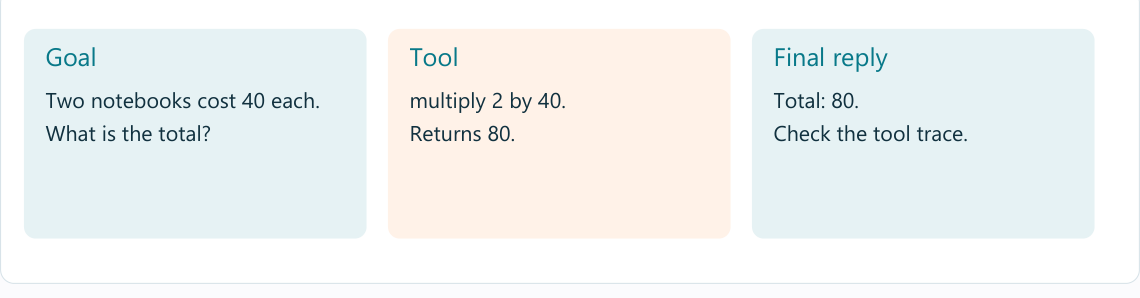

## Try a fresh input

Run a fresh two-step question and set a recursion limit to stop repeated loops.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-agents).